# Stuart–Landau oscillator: end-to-end phase inference in three measurement regimes

Physical parameters: $D_x = 10^{-3}$, $a = b = 1$, so $\tau_r = 1/(2a) = 0.5$ and
$D_{\rm eff} = D_x(1+b^2/a^2) = 2\times10^{-3}$. Every case fits $N_{\rm INF} = 32000$ samples.

The estimator is the extended-Kalman / generalized-EM estimator of `SyntheticPhaseNonlinearMeasurement`
(identical code in `StuartLandauPhaseInference.py`), run through the O(N) implementation in
`FastPhaseEM.py`. The pipeline is FFT frequency → initial-phase prior → weak conjugate priors →
generalized EM → Laplace covariance. It fits a random-walk phase seen through
$y_k = (\cos\theta_k,\sin\theta_k) + \eta_k$, with $\eta_k\sim\mathcal N(0,R\,I_2)$.

| section | added noise | $\Delta t$ | what it tests |
|---|---|---|---|
| §0 | — | — | the simulator against the analytical limits ($D_x$, $D_{\rm eff}$, OU crossover, radial variance, frequency) |
| Case 1 | $\sigma_{\rm add} = 0.125$, $R_{\rm add} = 0.0156 = 31\,D_x/2a$ | 0.02 | isotropic measurement noise dominating the amplitude noise; chosen so the pseudo-true $D^\ast = 0.80\,D_{\rm eff}$ |
| Case 2 | none | 2.16 $= 4.3\tau_r$ | amplitude fluctuations decorrelated between samples ($e^{-2a\Delta t} = 0.013$), so $R \to D_x/2a$; chosen so $D^\ast = 0.80\,D_{\rm eff}$ |
| Case 3 | none | 0.02 | amplitude fluctuations correlated over $\sim 25$ samples |
| Case 2b | none | 2.16 | **limiting regime of case 2**: amplitude relaxation $\tau_r = 0.005 \ll \Delta t$ ($a = b = 100$) and weaker noise ($D_x = 10^{-4}$) so that the EKF condition $2D\Delta t \ll 1$ holds |
| Case 3b | none | 0.02 | **limiting regime of case 3**: $\tau_r = 10^{-4} \ll \Delta t$ ($a = b = 5000$) at the same sampling |

Cases 1 and 2 are the two regimes in which the regime map of `InferenceExplainer.ipynb` §9 says the estimator
recovers most of $D_{\rm eff}$; case 3 is the regime where it does not. Without added noise the pseudo-true value
follows the limiting law $D^\ast = D_{\rm eff}(1 - \tau_r/\Delta t)$ (section before the summary); cases 2b and 3b
realise $\Delta t/\tau_r \ge 200$, where $D_{\rm eff}$ should fall inside the 95 % interval. A section before the
summary checks the consistency with Example 1b (`../SyntheticPhaseNonlinearMeasurement`): identical code, the same
pipeline step by step, and the three parameter conditions of `SPNM_Performance` evaluated for every case. Every case draws the pseudo-true
$D^\ast$ of `InferenceExplainer` §5 (dash-dotted), the value the estimator converges to as $N\to\infty$.

Each case ends with a figure in the layout of `SP_Parameters_v2`:
- row **a** shows the marginal posteriors of $\omega$, $D_\theta$ and $R$;
- row **b** shows the joint posteriors;
- reference values are black lines.

The axes always include the reference values, so a posterior far from its reference shows up as a spike
away from the line.

The SDE (Itô) is

$$dx_1 = [a(1-r^2)x_1 - (1+b(r^2-1))x_2]\,dt + \sqrt{2D_x}\,dW_1,\qquad
  dx_2 = [a(1-r^2)x_2 + (1+b(r^2-1))x_1]\,dt + \sqrt{2D_x}\,dW_2 .$$

**Runtime** is about 35–40 min. The $N = 32000$ Laplace covariances take 1–3 min each; case 2 integrates
$T \approx 69\,000$ (35 M Euler–Maruyama steps, about 5 min), case 2b 69 M steps (about 11 min) and case 3b
32 M steps (about 5 min).

In [1]:
from pathlib import Path
import time

from dataclasses import replace

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

import StuartLandauSimulation as SLS
import StuartLandauPhaseInference as SLPI
import FastPhaseEM
import NoiseInjectionSweep as NIS
import figstyle as fs

%config InlineBackend.figure_format = 'retina'
cmap = plt.cm.viridis
PLOTS = Path('plots')
PLOTS.mkdir(exist_ok=True)

## 0 · Model and its analytical limits

The physical parameters are those of the Figure-2 study (`NoiseInjectionSweep.Config`).

In [2]:
cfg = NIS.Config()
a, b, Dx = cfg.a, cfg.b, cfg.Dx     # [1/time], [dimensionless], [length^2/time]
dt = cfg.dt                         # Euler-Maruyama step [time]
D_eff = cfg.D_eff                   # long-lag phase diffusivity Dx (1 + b^2/a^2) [rad^2/time]
tau_r = cfg.tau_r                   # radial relaxation time 1/(2a) [time]
sigma_rho = cfg.sigma_rho           # rms radial fluctuation sqrt(Dx/2a) [length]

print(f"a = {a}, b = {b}, Dx = {Dx:.1e}, dt = {dt}")
print(f"tau_r = {tau_r} time,  sigma_rho = {sigma_rho:.4f}  (weak noise: << 1)")
print(f"D_x = {Dx:.1e},  D_eff = {D_eff:.1e} rad^2/time")
print(f"dt / tau_r = {dt / tau_r:.3f},  sqrt(2 Dx dt) = {np.sqrt(2 * Dx * dt):.4f}")

a = 1.0, b = 1.0, Dx = 1.0e-03, dt = 0.002
tau_r = 0.5 time,  sigma_rho = 0.0224  (weak noise: << 1)
D_x = 1.0e-03,  D_eff = 2.0e-03 rad^2/time
dt / tau_r = 0.004,  sqrt(2 Dx dt) = 0.0020


### 0a · Ensemble phase MSD vs theory

Two phases are tracked:
- the geometric phase $\theta = \arg(x_1 + i x_2)$;
- the asymptotic phase $\Phi = \theta + (b/a)\ln r$.

Linearised theory makes three predictions for trajectories started on the limit cycle ($\rho(0)=0$):
- $\langle\phi_\theta^2\rangle$ follows the OU crossover from $2D_x t$ at $t\ll\tau_r$ to
  $2D_{\rm eff}t$ at $t\gg\tau_r$;
- $\langle\phi_\Phi^2\rangle = 2D_{\rm eff}t$ at all $t$;
- radial fluctuations are Ornstein–Uhlenbeck, so $\mathrm{Var}[\rho]\to D_x/2a$.

The ensemble is $M = 6400$ realizations, simulated in 16 independent batches of 400 to bound memory.
The spread between batches gives a model-free standard error at every lag. The shaded bands in the plot
are $\pm2$ s.e.

**What the residual spread is.** It is finite-ensemble noise, with relative s.e. $\approx\sqrt{2/M}$
(1.8 % here). Every lag is measured from the same origin $t=0$ on the same trajectories, so the errors at
neighbouring lags are correlated. With a small ensemble they show up as smooth bumps around the theory
curve rather than as point-to-point scatter.

For the same reason the per-lag $z$-values in the table are not independent tests: a pair of
$|z|\approx 2$–$3$ at neighbouring lags is one excursion. Independent seed sets put such excursions at
different lags and with either sign. The summary tests are the long-lag fit and the rms deviation against
$\sqrt{2/M}$.

The long-lag diffusivity is fitted over $t>5\tau_r$ and tested against $D_{\rm eff}$ with the same
batch standard error. The last column of the per-lag table shows the OU curve going from $2D_xt$ to
$2D_{\rm eff}t$.

In [3]:
N_BATCH, M_BATCH = 16, 400   # 16 independent batches of 400 realizations: M = 6400
T_ENS = 20.0                  # simulated time [time] = 40 tau_r
N_ENS = int(round(T_ENS / dt))

t0 = time.time()
msd_theta_b, msd_Phi_b, var_rho_b, omega_b, r2m1_b = [], [], [], [], []
for i in range(N_BATCH):
    t, x1, x2, r, theta, Phi = SLS.simulate_stuart_landau(a=a, b=b, Dx=Dx, dt=dt, N=N_ENS,
                                                           M=M_BATCH, seed=1 + i)
    phi_theta, phi_Phi, om_theta, _ = SLS.compute_relative_phases(t, theta, Phi,
                                                                  subtract='empirical')
    msd_theta_b.append(SLS.compute_msd(phi_theta))      # ensemble MSD of this batch [rad^2]
    msd_Phi_b.append(SLS.compute_msd(phi_Phi))
    var_rho_b.append(np.var(r[:, t > 5 * tau_r] - 1.0))
    r2m1_b.append(np.mean(r[:, t > 5 * tau_r] ** 2 - 1.0))
    omega_b.append(om_theta)
del x1, x2, r, theta, Phi, phi_theta, phi_Phi           # ~200 MB per batch
msd_theta_b, msd_Phi_b = np.array(msd_theta_b), np.array(msd_Phi_b)

M_ENS = N_BATCH * M_BATCH
msd_theta, msd_Phi = msd_theta_b.mean(0), msd_Phi_b.mean(0)
se_theta = msd_theta_b.std(0, ddof=1) / np.sqrt(N_BATCH)   # per-lag s.e. [rad^2]
se_Phi = msd_Phi_b.std(0, ddof=1) / np.sqrt(N_BATCH)
theory = SLS.theoretical_curves(t, a, b, Dx)
print(f"simulated {M_ENS} x {N_ENS} steps in {time.time() - t0:.1f} s")

# each batch subtracts its own mean frequency; the residual drift error is negligible at short lags
d_om = np.std(omega_b, ddof=1)
k1 = int(round(1.0 / dt))
print(f"batch frequency spread {d_om:.1e} rad/time -> (d_omega t)^2 / MSD at t = 1: "
      f"{(d_om * 1.0) ** 2 / msd_theta[k1]:.1e}")

# long-lag diffusivity, tested against D_eff with the batch standard error
print(f"\n{'quantity':<34} {'simulated':>11} {'theory':>11} {'z':>6}")
for lbl, msd_b in (('D_long, geometric phase theta', msd_theta_b), ('D_long, asymptotic phase Phi', msd_Phi_b)):
    D_b = np.array([SLS.fit_long_time_diffusivity(t, mb, tau_r)[0] for mb in msd_b])
    D_hat, D_se = D_b.mean(), D_b.std(ddof=1) / np.sqrt(N_BATCH)
    print(f"{lbl:<34} {D_hat:11.4e} {D_eff:11.4e} {(D_hat - D_eff) / D_se:6.2f}")

# OU curve at individual lags, in units of the batch standard error
print(f"\n{'lag t':>6} {'MSD_theta/OU':>13} {'z':>6} {'OU/(2 Dx t)':>12}")
z_all = []
for t_chk in (0.02, 0.04, 0.1, 0.2, 0.5, 1.0, 2.0, 10.0):
    k = int(round(t_chk / dt))
    ou = theory['MSD_theta_OU'][k]
    z = (msd_theta[k] - ou) / se_theta[k]
    z_all.append(z)
    print(f"{t_chk:6.2f} {msd_theta[k] / ou:13.3f} {z:6.2f} {ou / (2 * Dx * t[k]):12.3f}")
small = (t >= 0.02) & (t <= 1.0)
rms = np.sqrt(np.mean((msd_theta[small] / theory['MSD_theta_OU'][small] - 1) ** 2))
print(f"rms relative deviation over 0.02 <= t <= 1: {rms:.3f}   (sqrt(2/M) = {np.sqrt(2 / M_ENS):.3f})")

var_rho = np.mean(var_rho_b)
print(f"\nVar[rho] (t > 5 tau_r) = {var_rho:.3e} +/- {np.std(var_rho_b, ddof=1) / np.sqrt(N_BATCH):.1e}"
      f"   OU theory Dx/2a = {Dx / (2 * a):.3e}")

simulated 6400 x 10000 steps in 8.2 s
batch frequency spread 6.0e-04 rad/time -> (d_omega t)^2 / MSD at t = 1: 1.3e-04

quantity                             simulated      theory      z
D_long, geometric phase theta       1.9755e-03  2.0000e-03  -0.53
D_long, asymptotic phase Phi        1.9761e-03  2.0000e-03  -0.50

 lag t  MSD_theta/OU      z  OU/(2 Dx t)
  0.02         1.011   0.61        1.001
  0.04         1.045   2.94        1.002
  0.10         1.039   2.62        1.012
  0.20         1.007   0.43        1.040
  0.50         1.022   1.17        1.168
  1.00         1.021   1.91        1.381
  2.00         1.034   1.74        1.634
 10.00         0.976  -1.55        1.925
rms relative deviation over 0.02 <= t <= 1: 0.019   (sqrt(2/M) = 0.018)

Var[rho] (t > 5 tau_r) = 5.030e-04 +/- 1.6e-06   OU theory Dx/2a = 5.000e-04


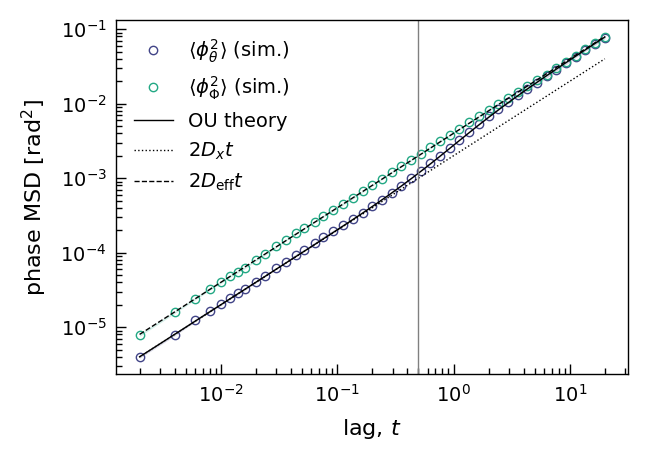

In [4]:
# ~12 log-spaced markers per decade, so short lags are not under-sampled on the log axis
k_log = np.unique(np.rint(np.geomspace(1, t.size - 1, 12 * 4 + 1)).astype(int))
pos = t > 0

fig, ax = fs.figax(6.5, 4.5)
for msd, se, col, lbl in ((msd_theta, se_theta, fs.C_DATA, r'$\langle\phi_\theta^2\rangle$ (sim.)'),
                          (msd_Phi, se_Phi, fs.C_MODEL, r'$\langle\phi_\Phi^2\rangle$ (sim.)')):
    ax.fill_between(t[k_log], (msd - 2 * se)[k_log], (msd + 2 * se)[k_log], color=col, **fs.BAND)
    ax.loglog(t[k_log], msd[k_log], **fs.MSD_PTS, color=col, label=lbl)
ax.loglog(t[pos], theory['MSD_theta_OU'][pos], **fs.THEORY, color='k', label='OU theory')
ax.loglog(t[pos], 2 * Dx * t[pos], color='k', lw=0.5, ls=':', label=r'$2D_x t$')
ax.loglog(t[pos], 2 * D_eff * t[pos], color='k', lw=0.5, ls='--', label=r'$2D_{\rm eff} t$')
ax.axvline(tau_r, color='0.5', lw=0.5)
fs.style_axes(ax, xlabel=r'lag, $t$', ylabel=r'phase MSD [rad$^2$]')
fs.legend(ax, loc='upper left')
fs.save(fig, PLOTS / 'SL_PhaseMSD_Theory.pdf')
plt.show()

### 0b · The frequency of the simulated process

The mean frequency is $\omega = 1 + b\,\langle r^2-1\rangle$.
- For the continuous-time SDE the stationary density of $u = r^2$ is Gaussian about 1, so
  $\langle r^2-1\rangle = 0$ and $\omega = 1$.
- Euler–Maruyama is different. Each explicit step of the rotation inflates $r^2$ by $(1+dt^2)$, and
  balancing that against the radial relaxation gives $\langle r^2-1\rangle \approx dt/(2a) = 10^{-3}$
  at $dt = 0.002$.

At $N_{\rm INF}=32000$ the frequency posterior is narrow enough for this offset to matter. The reference
line for $\omega$ is therefore the simulated process's own frequency, $\omega_{\rm sim}$, measured from
the §0 ensemble.

In [5]:
r2m1 = np.mean(r2m1_b)
r2m1_se = np.std(r2m1_b, ddof=1) / np.sqrt(N_BATCH)
OMEGA_SIM = 1.0 + b * r2m1          # mean frequency of the simulated (Euler-Maruyama) process [rad/time]
print(f"<r^2 - 1> = {r2m1:.3e} +/- {r2m1_se:.1e}   Euler-Maruyama prediction dt/(2a) = {dt / (2 * a):.1e}")
print(f"omega_sim = {OMEGA_SIM:.5f} rad/time   (continuous-time SDE: 1)")

<r^2 - 1> = 1.187e-03 +/- 1.1e-04   Euler-Maruyama prediction dt/(2a) = 1.0e-03
omega_sim = 1.00119 rad/time   (continuous-time SDE: 1)


## Shared helpers

`infer` runs the pipeline of `NoiseInjectionSweep.fit_window`: the 'default' initialization, the same
priors and the same EM tolerance. It returns the full $3\times3$ Laplace covariance of
$(\omega, \ln D, \ln R)$; the sweep stores only its diagonal.

`plot_parameter_posteriors` maps that Gaussian to natural coordinates:
- marginals: Gaussian for $\omega$, lognormal for $D$ and $R$;
- joints: the bivariate normal divided by its Jacobian, as in `SyntheticPhaseLinearMeasurement`.

It prints $\int p = 1$ checks for all six panels.

In [6]:
from scipy.optimize import minimize

# ── pseudo-true parameters (InferenceExplainer section 5): Whittle KL projection of the SL data onto the
#    random-walk + white-noise model, summed over the tangential and the radial channel ──
LAM = np.concatenate([np.geomspace(1e-9, 1e-2, 3000, endpoint=False), np.linspace(1e-2, np.pi, 4000)])


def S_model(lam, D, R, dt):
    """Model spectral density of tangential increments, per sample [rad^2]."""
    return 2 * D * dt + 2 * R * (1 - np.cos(lam))


def S_true(lam, sigma_add, dt, a=a, b=b, Dx=Dx):
    """Exact (linearised) spectral density of increments of the measured SL angle, per sample [rad^2].

    ``a``, ``b``, ``Dx`` default to the section-0 oscillator; the stiff-amplitude cases pass their own.
    """
    c = np.exp(-2 * a * dt)
    k = (2 * b) ** 2 * Dx / (2 * a)                    # (2b)^2 sigma_rho^2
    g0 = 2 * Dx * dt + k * 2 * (dt / (2 * a) - (1 - c) / (2 * a) ** 2)
    B = k * (1 - c) ** 2 / (2 * a) ** 2
    z = np.exp(1j * lam)
    return g0 + 2 * B * np.real(z / (1 - c * z)) + 2 * sigma_add ** 2 * (1 - np.cos(lam))


def kl_projection(sigma_add, dt, a=a, b=b, Dx=Dx):
    """Pseudo-true (D*, R*) the estimator converges to as N -> infinity.

    Parameters
    ----------
    sigma_add : float
        Injected isotropic Cartesian noise sd [length].
    dt : float
        Sampling interval [time].
    a, b, Dx : float
        Oscillator parameters [1/time], [-], [length^2/time]; default to the section-0 values.

    Returns
    -------
    dict
        ``D`` [rad^2/time] and ``R`` [length^2].
    """
    S = S_true(LAM, sigma_add, dt, a, b, Dx)
    V_rad = Dx / (2 * a) + sigma_add ** 2             # radial-channel variance [length^2]
    D_eff_ab = Dx * (1 + b ** 2 / a ** 2)

    def objective(p):
        D, R = np.exp(p)
        Sm = S_model(LAM, D, R, dt)
        return np.trapezoid(np.log(Sm) + S / Sm, LAM) / np.pi + np.log(R) + V_rad / R

    opt = minimize(objective, np.log([D_eff_ab, V_rad]), method='Nelder-Mead',
                   options=dict(xatol=1e-10, fatol=1e-16, maxiter=8000))
    D, R = np.exp(opt.x)
    return dict(D=D, R=R)


def ref_Dstar(sigma_add, dt, a=a, b=b, Dx=Dx):
    """Reference-line tuple for the pseudo-true D*, in the format `plot_parameter_posteriors` expects."""
    return (kl_projection(sigma_add, dt, a, b, Dx)['D'], '-.', r'$D^\ast$', 'D*')


def infer(tk, yk, cfg):
    """EKF / generalized-EM MAP fit with the full Laplace covariance.

    Same steps, priors and settings as `NoiseInjectionSweep.fit_window` ('default' init), but
    returns the full 3x3 covariance of (omega, ln D, ln R) that the joint posteriors need.

    Parameters
    ----------
    tk : ndarray, shape (N,)
        Uniformly spaced sample times [time].
    yk : ndarray, shape (N, 2)
        Cartesian measurements [length].
    cfg : NoiseInjectionSweep.Config
        Supplies ``window_size``, ``max_iter`` and ``tol``.

    Returns
    -------
    dict
        ``lambda_map`` (omega, ln D, ln R); ``cov`` 3x3 Laplace covariance in the same
        coordinates; ``lam`` EM path; ``converged``; ``n_em``; ``rho`` EM contraction rate;
        ``omega_FFT``, ``R_init``, ``D_init`` (initialization); ``wall_em``, ``wall_cov`` [s];
        ``state_priors``, ``priors`` as used.
    """
    data = (tk, yk)
    r_inf = np.hypot(yk[:, 0], yk[:, 1])

    # 1) frequency seed, 2) radial noise heuristic + initial-phase prior, 3) conjugate priors
    omega_FFT, _, _ = SLPI.estimate_frequency_fft(data)                       # [rad/time]
    R_init = max(0.5 * float(np.mean((r_inf - 1.0) ** 2)), 1e-7)              # [length^2]
    pinit = SLPI.estimate_initial_phase_regression(data, omega_FFT, cfg.window_size, R_init)
    state_priors = (pinit['phi_mean'] + omega_FFT * tk[0], max(2.0 * pinit['phi_std'], 0.01))
    D_init = max(R_init / 20.0, 1e-7)                                         # [rad^2/time]
    priors = state_priors + (omega_FFT, omega_FFT, 2.0, 2.0 * D_init, 2.0, 2.0 * R_init)

    # 4) generalized EM to convergence
    t0 = time.time()
    lam, converged = FastPhaseEM.em_map_parameters_fast(
        [omega_FFT, np.log(D_init), np.log(R_init)], data, priors,
        max_iter=cfg.max_iter, tol=cfg.tol, param_mode='log', warn=False)
    wall_em = time.time() - t0
    lambda_map = lam[-1]

    # 5) Laplace covariance of the frozen surrogate at the MAP (Louis identity)
    t0 = time.time()
    Hk, ck, _ = SLPI.freeze_linearization(lambda_map, data, state_priors)
    post = FastPhaseEM.posterior_information_fast(lambda_map, data, priors, Hk, ck,
                                                  param_type='log')
    return dict(lambda_map=lambda_map, cov=post['cov'], lam=lam, converged=converged,
                n_em=len(lam) - 1, rho=post['rho'], omega_FFT=float(omega_FFT),
                R_init=R_init, D_init=D_init, wall_em=wall_em, wall_cov=time.time() - t0,
                state_priors=state_priors, priors=priors)


def summarize(fit, refs):
    """Print MAP, 95 % interval and ratio to each reference value; return the rows.

    Parameters
    ----------
    fit : dict
        Output of `infer`.
    refs : dict
        ``{'omega': [(value, ls, tex, name), ...], 'D': [...], 'R': [...]}``.

    Returns
    -------
    dict
        Parameter name -> (MAP, lo95, hi95) in natural units.
    """
    mu, sd = fit['lambda_map'], np.sqrt(np.diag(fit['cov']))
    rows = {}
    print(f"EM: {fit['n_em']} iterations, converged = {fit['converged']}, {fit['wall_em']:.0f} s; "
          f"Laplace covariance {fit['wall_cov']:.0f} s; EM contraction rate rho = {fit['rho']:.4f}")
    print(f"{'':>6} {'MAP':>11} {'95% interval':>25}   relative to reference")
    for i, (key, unit) in enumerate((('omega', 'rad/time'), ('D', 'rad^2/time'), ('R', 'length^2'))):
        if i == 0:
            m, lo, hi = mu[0], mu[0] - 1.96 * sd[0], mu[0] + 1.96 * sd[0]
        else:
            m, lo, hi = np.exp(mu[i]), np.exp(mu[i] - 1.96 * sd[i]), np.exp(mu[i] + 1.96 * sd[i])
        rel = ', '.join(f"{m / v:.3f} x {name}" for v, _, _, name in refs[key])
        print(f"{key:>6} {m:11.4e} [{lo:11.4e}, {hi:11.4e}]   = {rel}   [{unit}]")
        rows[key] = (m, lo, hi)
    return rows


PARAM_LABELS = (r'frequency, $\omega$', r'diffusivity, $D_\theta$', r'noise, $R$')
PARAM_KEYS = ('omega', 'D', 'R')


def plot_parameter_posteriors(fit, refs, path, n_sd=5.0):
    """Laplace posterior figure in the layout of SP_Parameters_v2.

    Row a: marginal posteriors of omega (Gaussian), D and R (lognormal). Row b: joint posteriors
    of (omega, D), (omega, R), (D, R) -- the Laplace Gaussian in (omega, ln D, ln R), mapped to
    natural coordinates with its Jacobian. Axes span MAP +/- `n_sd` sd and every reference value,
    so a reference far from the posterior is still drawn.

    Parameters
    ----------
    fit : dict
        Output of `infer`.
    refs : dict
        ``{'omega': [(value, ls, tex, name), ...], 'D': [...], 'R': [...]}``; drawn as black
        lines and labelled with `tex` above the marginal panels.
    path : Path
        PDF destination.
    n_sd : float
        Half-width of the posterior window, in posterior standard deviations.

    Returns
    -------
    matplotlib.figure.Figure
    """
    mu, cov = np.asarray(fit['lambda_map'], float), np.asarray(fit['cov'], float)
    sd = np.sqrt(np.diag(cov))
    to_nat = (lambda u: u, np.exp, np.exp)            # (omega, ln D, ln R) -> natural
    jac = (lambda x: np.ones_like(x), lambda x: x, lambda x: x)   # d(natural)/d(param)

    # axis limits: posterior window plus every reference, padded by 8 %; D and R are shown
    # in units of a power of ten that goes into the axis label
    lims, scale, labels = [], [], []
    for i, key in enumerate(PARAM_KEYS):
        pts = [to_nat[i](mu[i] - n_sd * sd[i]), to_nat[i](mu[i] + n_sd * sd[i])]
        pts += [v for v, *_ in refs[key]]
        lo, hi = min(pts), max(pts)
        e = 0 if i == 0 else int(np.floor(np.log10(hi)))
        scale.append(10.0 ** e)
        lims.append(((lo - 0.08 * (hi - lo)) / 10.0 ** e, (hi + 0.08 * (hi - lo)) / 10.0 ** e))
        labels.append(PARAM_LABELS[i] if e == 0 else PARAM_LABELS[i] + rf' ($\times 10^{{{e}}}$)')

    # fixed geometry: 14.6 x 9.4 cm, six 3.3 x 2.9 cm frames
    W, H = 14.6, 9.4
    fig = plt.figure(figsize=(W * fs.CM, H * fs.CM))
    xcol, wax, hax = (1.35, 6.2, 11.05), 3.3, 2.9
    rows = {'a': 5.5, 'b': 1.05}
    add = lambda x0, y0: fig.add_axes([x0 / W, y0 / H, wax / W, hax / H])
    for lab, y0 in rows.items():
        fig.text(0.15 / W, (y0 + hax + 0.25) / H, lab, fontsize=10, va='bottom')

    checks = []
    # row a: marginals
    for i, key in enumerate(PARAM_KEYS):
        ax = add(xcol[i], rows['a'])
        u_fine = np.linspace(mu[i] - 6 * sd[i], mu[i] + 6 * sd[i], 801)
        x = np.unique(np.concatenate([np.linspace(*lims[i], 401) * scale[i], to_nat[i](u_fine)]))
        x = x[(x >= lims[i][0] * scale[i]) & (x <= lims[i][1] * scale[i]) & (x > (0 if i else -np.inf))]
        if i == 0:
            pdf = stats.norm.pdf(x, loc=mu[0], scale=sd[0])
        else:
            pdf = stats.lognorm.pdf(x, s=sd[i], scale=np.exp(mu[i]))
        checks.append((f'{key}', np.trapezoid(pdf, x)))
        xs, pdfs = x / scale[i], pdf * scale[i]          # density per displayed unit
        ax.plot(xs, pdfs, color=cmap(0.2), lw=1)
        ax.fill_between(xs, pdfs, color=cmap(0.2), alpha=0.1, lw=0)
        for v, ls, tex, _ in refs[key]:
            ax.axvline(v / scale[i], color='k', ls=ls, lw=1)
            ax.text(v / scale[i], 1.03, tex, transform=ax.get_xaxis_transform(),
                    ha='center', va='bottom', fontsize=fs.FS_TICK)
        ax.set_xlim(*lims[i])
        fs.style_axes(ax, xlabel=labels[i])

    # row b: joints
    for col, (i, j) in enumerate(((0, 1), (0, 2), (1, 2))):
        ax = add(xcol[col], rows['b'])
        ui = np.linspace(mu[i] - n_sd * sd[i], mu[i] + n_sd * sd[i], 301)
        uj = np.linspace(mu[j] - n_sd * sd[j], mu[j] + n_sd * sd[j], 301)
        UI, UJ = np.meshgrid(ui, uj)
        Z = stats.multivariate_normal(mu[[i, j]], cov[np.ix_([i, j], [i, j])]).pdf(np.dstack((UI, UJ)))
        XI, XJ = to_nat[i](UI), to_nat[j](UJ)
        Znat = Z / (jac[i](XI) * jac[j](XJ))
        checks.append((f'{PARAM_KEYS[i]}-{PARAM_KEYS[j]}',
                       np.trapezoid(np.trapezoid(Znat, XI[0], axis=1), XJ[:, 0])))
        ax.contour(XI / scale[i], XJ / scale[j], Znat, levels=10, linewidths=1)
        for v, ls, *_ in refs[PARAM_KEYS[i]]:
            ax.axvline(v / scale[i], color='k', ls=ls, lw=0.5)
        for v, ls, *_ in refs[PARAM_KEYS[j]]:
            ax.axhline(v / scale[j], color='k', ls=ls, lw=0.5)
        ax.set_xlim(*lims[i]); ax.set_ylim(*lims[j])
        fs.style_axes(ax, xlabel=labels[i], ylabel=labels[j])

    fs.save(fig, path)
    print('normalization (should be ~1): ' + ', '.join(f'{k} {v:.4f}' for k, v in checks))
    return fig

In [7]:
# the Figure-2 trajectory (Delta t = 0.02), integrated as far as N_INF = 32000 needs
fcfg = NIS.figure_config()
t0 = time.time()
traj = NIS.simulate_ensemble(fcfg, thin=True)
print(f"8 realizations to T = {fcfg.N_INF_max * fcfg.delta_t_inf:.0f} in {time.time() - t0:.1f} s")

N_INF, REP = 32000, 0
sweep = pd.read_parquet(Path('data') / 'sweep_results.parquet')

def check_against_sweep(fit, sigma_add):
    '''Assert `fit` reproduces the cached Figure-2 row for (sigma_add, N_INF, REP, 'default').'''
    ref = sweep[(sweep.init_mode == 'default') & (sweep.N_INF == N_INF)
                & (sweep.rep == REP) & (sweep.sigma_add == sigma_add)].iloc[0]
    mine = dict(omega_map=fit['lambda_map'][0], D_map=np.exp(fit['lambda_map'][1]),
                R_map=np.exp(fit['lambda_map'][2]), lnD_std=np.sqrt(fit['cov'][1, 1]),
                n_em=fit['n_em'])
    for k, v in mine.items():
        assert np.isclose(v, ref[k], rtol=1e-12, atol=0), f'{k}: {v} vs cached {ref[k]}'
    print(f"identical to the data/sweep_results.parquet row (sigma_add={sigma_add}, N_INF={N_INF}, "
          f"rep={REP}): {', '.join(mine)}")

REF_OMEGA = [(OMEGA_SIM, '--', r'$\omega_{\rm sim}$', 'omega_sim')]
REF_D = [(D_eff, '--', r'$D_{\rm eff}$', 'D_eff'), (Dx, ':', r'$D_x$', 'D_x')]
summary = {}

8 realizations to T = 640 in 3.5 s


## Case 1 · Added measurement noise, $R_{\rm add} \gg D_x/2a$

Isotropic Cartesian noise with $\sigma_{\rm add} = 0.125$ is added to every sample, so
$R_{\rm add} = \sigma_{\rm add}^2 = 0.0156$. That is 31 times the radial variance $D_x/2a$. The angular
error it causes is $\sigma_\psi \approx 0.125$ rad, still inside the EKF's linearisation.

**Why this noise level.** The pseudo-true diffusivity of `InferenceExplainer` §5, $D^\ast(\sigma_{\rm add},\Delta t)$,
is $0.80\,D_{\rm eff}$ at $\sigma_{\rm add}=0.125$ (it is $0.31\,D_{\rm eff}$ without noise, case 3). The noise moves the
filter's information window $\tau^\ast=\sqrt{R\Delta t/2D}\approx0.3$ up to the order of $\tau_r$, so the amplitude
memory is no longer read as short-lag phase motion to be smoothed away.

**Reference for $R$: $\sigma_{\rm add}^2 + D_x/4a$.** The injected variance is isotropic. The amplitude
fluctuation adds $D_x/2a$ in the radial direction only, which the isotropic model spreads over two
components.

This noise level is not on the Figure-2 grid, so there is no cached row to compare with. A single
$N_{\rm INF}=32000$ realisation scatters around $D^\ast$ by about 7 % (the sweep's replicate spread at the
bracketing grid points $\sigma_{\rm add}=0.1$ and $0.15$ is printed below), so the fit is expected within
$0.75$–$0.85\,D_{\rm eff}$.


N_INF = 32000, Delta t = 0.020, T = 640 (102 cycles);  R_add = 1.6e-02 = 31 x Dx/2a



EM: 325 iterations, converged = True, 21 s; Laplace covariance 97 s; EM contraction rate rho = 0.9822
               MAP              95% interval   relative to reference
 omega  9.9729e-01 [ 9.9294e-01,  1.0016e+00]   = 0.996 x omega_sim   [rad/time]
     D  1.5753e-03 [ 1.4027e-03,  1.7692e-03]   = 0.788 x D_eff, 1.575 x D_x, 0.984 x D*   [rad^2/time]
     R  1.5814e-02 [ 1.5640e-02,  1.5991e-02]   = 0.996 x sigma_add^2 + Dx/4a   [length^2]

pseudo-true D* = 1.6008e-03 = 0.800 D_eff,  R* = 1.5845e-02   (KL projection, InferenceExplainer section 5)
sweep, sigma_add = 0.1: D_map/D_eff over 8 replicates = 0.780 +/- 0.065
sweep, sigma_add = 0.15: D_map/D_eff over 8 replicates = 0.833 +/- 0.075


normalization (should be ~1): omega 1.0000, D 1.0000, R 1.0000, omega-D 1.0000, omega-R 1.0000, D-R 1.0000


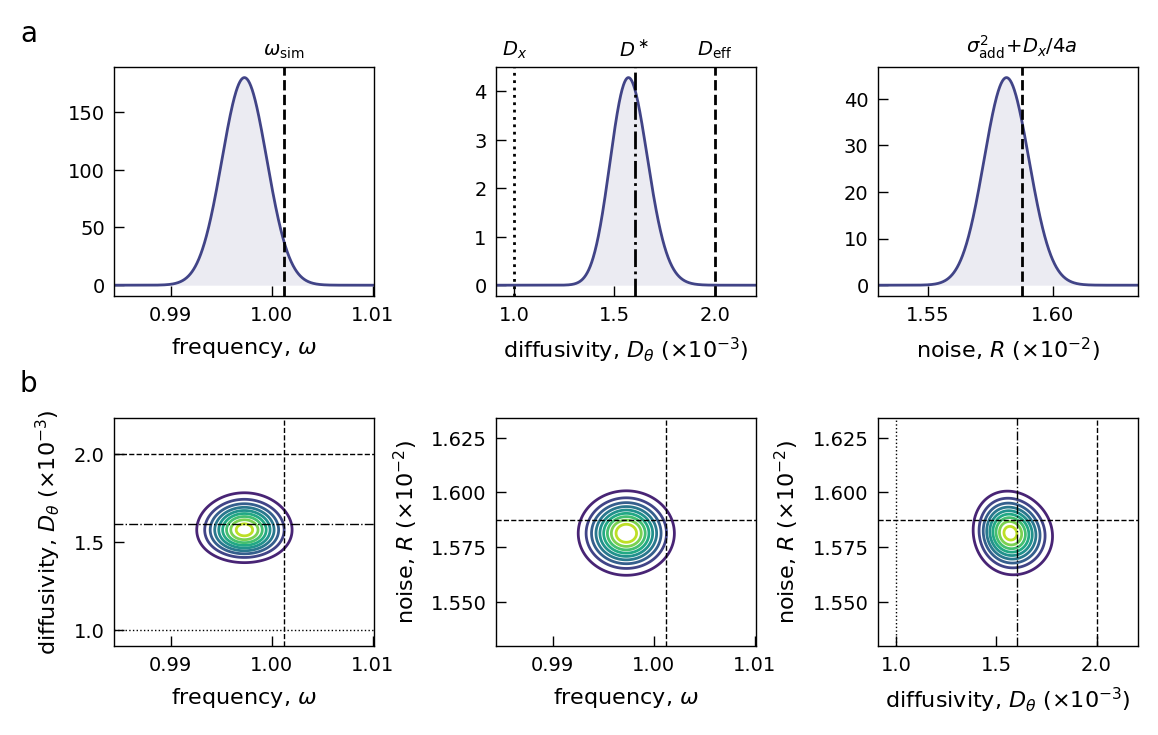

In [8]:
SIGMA_ADD = 0.125                                 # injected noise std per component [length]; D*(0.125, 0.02) = 0.80 D_eff
tk, yk, theta_win, Phi_win = NIS.make_window(traj, fcfg, SIGMA_ADD, N_INF, REP,
                                             NIS.noise_seed_for(fcfg, SIGMA_ADD, REP))
print(f"N_INF = {N_INF}, Delta t = {tk[1] - tk[0]:.3f}, T = {tk[-1] - tk[0]:.0f} "
      f"({(tk[-1] - tk[0]) / (2 * np.pi):.0f} cycles);  R_add = {SIGMA_ADD**2:.1e} = "
      f"{SIGMA_ADD**2 / (Dx / (2 * a)):.0f} x Dx/2a\n")

fit1 = infer(tk, yk, fcfg)
refs1 = {'omega': REF_OMEGA, 'D': REF_D + [ref_Dstar(SIGMA_ADD, fcfg.delta_t_inf)],
         'R': [(SIGMA_ADD**2 + Dx / (4 * a), '--', r'$\sigma_{\rm add}^2\!+\!D_x/4a$', 'sigma_add^2 + Dx/4a')]}
summary[f'1: sigma_add = {SIGMA_ADD}, Dt = 0.02'] = (summarize(fit1, refs1), refs1, fcfg.delta_t_inf)

# context: the pseudo-true D*, and the replicate scatter of the cached N_INF = 32000 fits at the bracketing noise levels
kp1 = kl_projection(SIGMA_ADD, fcfg.delta_t_inf)
print(f"\npseudo-true D* = {kp1['D']:.4e} = {kp1['D'] / D_eff:.3f} D_eff,  R* = {kp1['R']:.4e}   (KL projection, InferenceExplainer section 5)")
for s_ in (0.1, 0.15):
    g_ = sweep.query("init_mode == 'default' and N_INF == @N_INF and sigma_add == @s_").D_map / D_eff
    print(f"sweep, sigma_add = {s_}: D_map/D_eff over {len(g_)} replicates = {g_.mean():.3f} +/- {g_.std(ddof=1):.3f}")
fig = plot_parameter_posteriors(fit1, refs1, PLOTS / 'SL_Parameters_Case1_AddedNoise.pdf')
plt.show()

## Case 2 · No added noise, $\Delta t = 2.16 = 4.3\,\tau_r$

This case uses the same oscillator and the same $N_{\rm INF} = 32000$ as case 3, but samples every
$\Delta t = 2.16$ instead of every 0.02. That makes the window $T \approx 69\,000$, about 11 000 cycles. The
phase advances 2.16 rad per sample, 69 % of the Nyquist limit $\Delta t < \pi/\omega$ beyond which $\omega$
would alias.

**Why this sampling interval.** Coarse sampling is the noise-free route to the same end as case 1: the
pseudo-true $D^\ast(0,\Delta t)$ of `InferenceExplainer` §5 rises with $\Delta t/\tau_r$ (its §6, right panel) and
reaches $0.80\,D_{\rm eff}$ at $\Delta t = 2.16$. Nyquist caps $\Delta t$ at $\pi$, where $D^\ast = 0.85\,D_{\rm eff}$,
so this is close to the best coarse sampling can do at $a = b = 1$.

**What changes with $\Delta t$ is how correlated the amplitude error is between samples.** The radial
fluctuation $\rho$ relaxes at rate $2a$, so neighbouring samples are correlated by
$c = e^{-2a\Delta t}$. That is $0.96$ in case 3 (correlated over $\tau_r/\Delta t = 25$ samples) and
$c = e^{-4.3} = 0.013$ here: fully decorrelated.

**$R$ should sit at the decorrelated limit.** Measured from the asymptotic phase $\Phi = \theta + (b/a)\ln r$,
the measurement error is rank-1: a radial part $\rho$ and a tangential part $-(b/a)\rho$.
- The radial part, variance $D_x/2a$, is always measurement noise.
- The tangential part, variance $(b/a)^2D_x/2a$, is absorbed into the phase estimate while it is slow
  compared with the sampling, as in case 3, where $R \to D_x/4a$.
- Once it decorrelates between samples it becomes measurement noise too, and
  $R \to D_x(1+b^2/a^2)/4a$, which equals $D_x/2a$ for $a = b$.

Both limits are drawn: the decorrelated limit dashed, the correlated (case-3) limit dotted. The cell prints
where $R$ lies between them; here it should be close to 1.

**$D$ stays below $D_{\rm eff}$**, for two reasons that both shrink with $\Delta t$.
- **Shared noise.** The radial noise $dW_\rho$ drives both the phase increment $\Delta\Phi_k$ and the
  next measurement error $\rho_{k+1}$. Their covariance is $(b/a)(D_x/a)(1-c)$, which the model
  assumes is zero. This is the negative MSD intercept of `InferenceExplainer` §1b.
- **Shared $R$.** The radial channel feeds $R \approx \sigma_\rho^2$ into the phase filter, which costs a
  further $\approx\sigma_\rho^2/(D_{\rm eff}\Delta t)$ (its §6).

The cell prints a moment-matching estimate next to the fit. It matches
$\mathrm{Var}(\Delta\theta) = 2D_{\rm eff}\Delta t - (b/a)^2(D_x/a)(1-c)$ to the model's $2D\Delta t + 2R$,
which gives $D \approx D_{\rm eff} - [(b/a)^2(D_x/a)(1-c) + 2R]/(2\Delta t)$. At $c = 0.013$ the lag
correlations $c^k$ it ignores are negligible, and it lands within a few per cent of the fit and of $D^\ast$
(it over-counts the $2R$ term slightly, because the Whittle fit does not subtract the full white-noise variance).


Delta t = 2.16 = 4.3 tau_r: radial correlation e^(-2a Dt) = 0.013 (case 3: 0.961); phase step omega Dt = 2.2 rad (Nyquist limit pi)


integrated 34,560,000 steps in 300 s
N_INF = 32000, Delta t = 2.2, T = 69118 (11000 cycles)



EM: 17 iterations, converged = True, 1 s; Laplace covariance 40 s; EM contraction rate rho = 0.4845
               MAP              95% interval   relative to reference
 omega  1.0012e+00 [ 1.0007e+00,  1.0016e+00]   = 1.000 x omega_sim   [rad/time]
     D  1.5864e-03 [ 1.5590e-03,  1.6142e-03]   = 0.793 x D_eff, 1.586 x D_x, 0.991 x D*   [rad^2/time]
     R  5.3075e-04 [ 5.2276e-04,  5.3886e-04]   = 1.061 x Dx(1+b^2/a^2)/4a = Dx/2a, 2.123 x Dx/4a   [length^2]

R between its limits: (R - Dx/4a) / (Dx/2a - Dx/4a) = 1.12  (0 = correlated, 1 = decorrelated)
moment-matching estimate D ~ 1.526e-03 = 0.763 D_eff   (fit: 0.793 D_eff;  pseudo-true D*: 0.800 D_eff)


normalization (should be ~1): omega 1.0000, D 1.0000, R 1.0000, omega-D 1.0000, omega-R 1.0000, D-R 1.0000


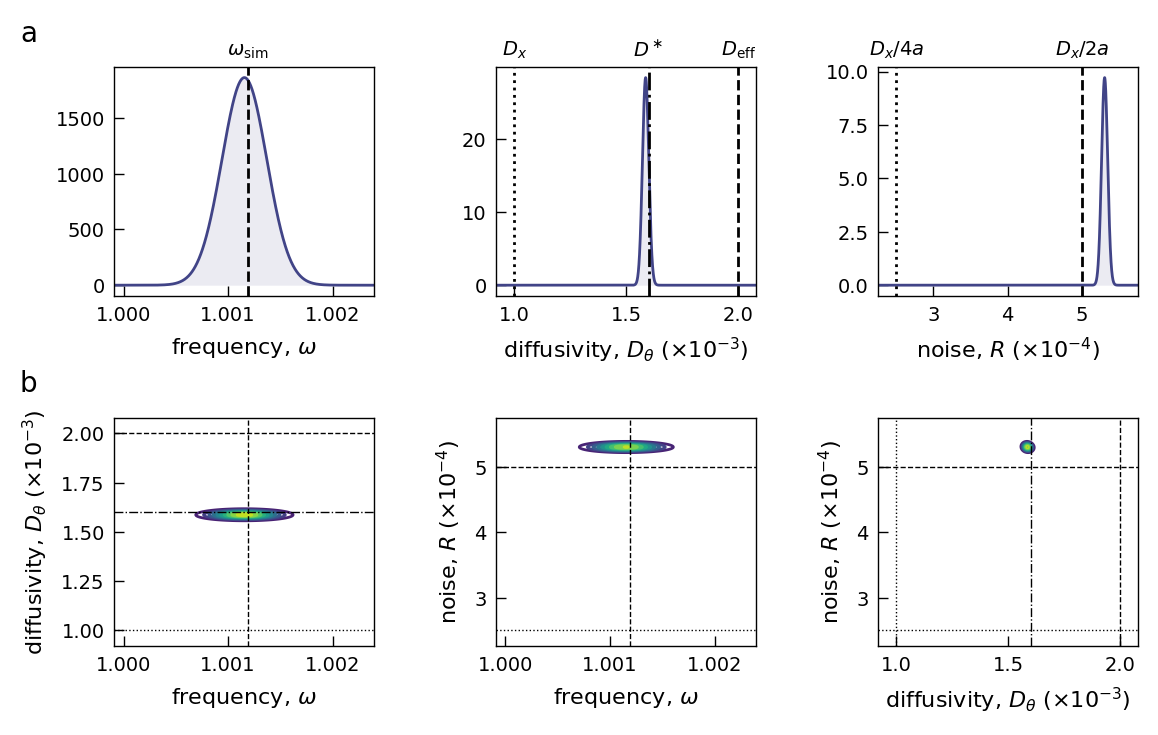

In [9]:
DT_2 = 2.16                                       # inference spacing [time]; D*(0, 2.16) = 0.80 D_eff, omega dt = 0.69 pi
cfg2 = replace(NIS.Config(), delta_t_inf=DT_2, n_rep=1, N_INF_max=N_INF)
c2 = np.exp(-2 * a * DT_2)                        # radial correlation between samples
print(f"Delta t = {DT_2} = {DT_2 / tau_r:.1f} tau_r: radial correlation e^(-2a Dt) = {c2:.3f} "
      f"(case 3: {np.exp(-2 * a * fcfg.delta_t_inf):.3f}); phase step omega Dt = {DT_2:.1f} rad "
      f"(Nyquist limit pi)")

t0 = time.time()
traj2 = NIS.simulate_ensemble(cfg2, thin=True)    # one realization, T = N_INF * DT_2, dt = 0.002
print(f"integrated {cfg2.N_steps:,} steps in {time.time() - t0:.0f} s")
tk2, yk2, _, _ = NIS.make_window(traj2, cfg2, 0.0, N_INF, 0, noise_seed=0)
print(f"N_INF = {N_INF}, Delta t = {tk2[1] - tk2[0]:.1f}, T = {tk2[-1] - tk2[0]:.0f} "
      f"({(tk2[-1] - tk2[0]) / (2 * np.pi):.0f} cycles)\n")

fit2 = infer(tk2, yk2, cfg2)
R_dec = Dx * (1 + b**2 / a**2) / (4 * a)          # decorrelated limit (= Dx/2a for a = b)
R_cor = Dx / (4 * a)                              # correlated limit (case 3)
refs2 = {'omega': REF_OMEGA, 'D': REF_D + [ref_Dstar(0.0, DT_2)],
         'R': [(R_dec, '--', r'$D_x/2a$', 'Dx(1+b^2/a^2)/4a = Dx/2a'),
               (R_cor, ':', r'$D_x/4a$', 'Dx/4a')]}
summary[f'2: no noise, Dt = {DT_2}'] = (summarize(fit2, refs2), refs2, DT_2)

R2 = np.exp(fit2['lambda_map'][2])
print(f"\nR between its limits: (R - Dx/4a) / (Dx/2a - Dx/4a) = {(R2 - R_cor) / (R_dec - R_cor):.2f}  "
      f"(0 = correlated, 1 = decorrelated)")
D_mm = D_eff - ((b / a)**2 * (Dx / a) * (1 - c2) + 2 * R2) / (2 * DT_2)
print(f"moment-matching estimate D ~ {D_mm:.3e} = {D_mm / D_eff:.3f} D_eff   "
      f"(fit: {np.exp(fit2['lambda_map'][1]) / D_eff:.3f} D_eff;  pseudo-true D*: {refs2['D'][2][0] / D_eff:.3f} D_eff)")
fig = plot_parameter_posteriors(fit2, refs2, PLOTS / 'SL_Parameters_Case2_LargeDt.pdf')
plt.show()

## Case 3 · No added noise, $\Delta t = 0.02$

This is the same trajectory and window as case 1, without injected noise. The amplitude fluctuation is
now correlated over $\tau_r/\Delta t = 25$ samples.

**Reference for $R$: $D_x/4a$.** The tangential part of the error, $-(b/a)\rho$, is slow, so the filter
absorbs it into the phase. Only the radial part, $D_x/2a$, is left as measurement noise, and it is spread
over two components.

This is the $R_{\rm add} = 0$ point of Figure 2. Short-lag phase motion is attributed to measurement
noise, and $D$ lands below even $D_x$. The pseudo-true value is $D^\ast = 0.31\,D_{\rm eff}$: this is the dark
region of the regime map (`InferenceExplainer` §9), where fine sampling and no noise let the filter read the
amplitude memory as measurement noise.

EM: 54 iterations, converged = True, 3 s; Laplace covariance 149 s; EM contraction rate rho = 0.8448
               MAP              95% interval   relative to reference
 omega  9.9727e-01 [ 9.9452e-01,  1.0000e+00]   = 0.996 x omega_sim   [rad/time]
     D  6.2600e-04 [ 6.0186e-04,  6.5110e-04]   = 0.313 x D_eff, 0.626 x D_x, 1.003 x D*   [rad^2/time]
     R  2.8654e-04 [ 2.8331e-04,  2.8981e-04]   = 1.146 x Dx/4a   [length^2]
identical to the data/sweep_results.parquet row (sigma_add=0.0, N_INF=32000, rep=0): omega_map, D_map, R_map, lnD_std, n_em
normalization (should be ~1): omega 1.0000, D 1.0000, R 1.0000, omega-D 1.0000, omega-R 1.0000, D-R 1.0000


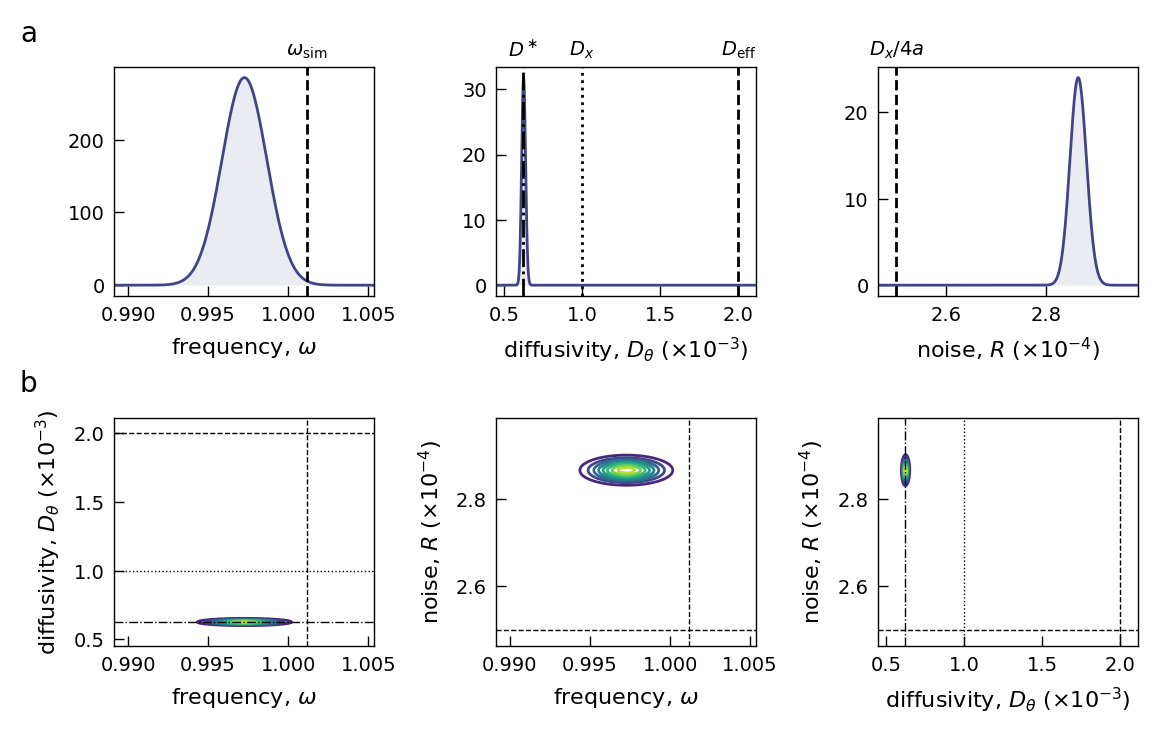

In [10]:
tk3, yk3, _, _ = NIS.make_window(traj, fcfg, 0.0, N_INF, REP, NIS.noise_seed_for(fcfg, 0.0, REP))
fit3 = infer(tk3, yk3, fcfg)
refs3 = {'omega': REF_OMEGA, 'D': REF_D + [ref_Dstar(0.0, fcfg.delta_t_inf)], 'R': [(Dx / (4 * a), '--', r'$D_x/4a$', 'Dx/4a')]}
summary['3: no noise, Dt = 0.02'] = (summarize(fit3, refs3), refs3, fcfg.delta_t_inf)
check_against_sweep(fit3, 0.0)
fig = plot_parameter_posteriors(fit3, refs3, PLOTS / 'SL_Parameters_Case3_NoNoise.pdf')
plt.show()

## Limiting regime without added noise: $\tau_r \ll \Delta t$

Cases 2 and 3 fall short of $D_{\rm eff}$ because the inference model is a coarse-grained description of the
oscillator: it has no amplitude. Without added noise the pseudo-true value of `InferenceExplainer` §5 depends
on the sampling only through $\Delta t/\tau_r = 2a\Delta t$, and for $\Delta t \gtrsim 20\,\tau_r$ it follows
$$
\frac{D^\ast}{D_{\rm eff}} \simeq 1 - \frac{\tau_r}{\Delta t},
\qquad\text{i.e.}\qquad
D^\ast \simeq D_{\rm eff} - \Big(1+\frac{b^2}{a^2}\Big)\frac{\sigma_\rho^2}{\Delta t},
$$
to better than 1 % for any $\Delta t$, $b/a$ and $D_x$ (checked numerically in the figure below). The two terms are
the two mechanisms of case 2: the chord deficit $(b/a)^2\sigma_\rho^2/\Delta t$ of the measured angle (shared
radial noise) and the shared-$R$ cost $\sigma_\rho^2/\Delta t$ from the radial channel. Both are the amplitude
variance divided by the sampling interval: **the coarse-grained model becomes exact when the amplitude relaxes
within one sample.**

Three conditions must hold at once for $D_{\rm eff}$ to fall inside the 95 % interval of an $N_{\rm INF} = 32000$
fit, whose half-width is $1.96\sqrt{2/N} = 1.55\,\%$:

| condition | origin | requirement |
|---|---|---|
| $\tau_r/\Delta t \ll 0.0155$ | model error above | $\Delta t/\tau_r \gtrsim 200$ |
| $2.4\times 2D_{\rm eff}\Delta t \ll 0.0155$ | EKF linearisation bias (`InferenceExplainer` §3d; the coefficient 2.4 is measured on model data with $R\to0$) | $D_{\rm eff}\Delta t \lesssim 10^{-3}$ |
| $\omega\Delta t < \pi$ | Nyquist | $\Delta t < \pi$ |

At $a = b = 1$ the first and third are incompatible: $\Delta t/\tau_r < 2\pi$, so $D^\ast \le 0.85\,D_{\rm eff}$.
Added noise circumvents this by moving the information window instead (case 1). **Without noise the oscillator
itself must relax its amplitude faster.** We keep $b = a$, so that $D_{\rm eff} = 2D_x$ stays well separated from
$D_x$, and raise $a$:

- **Case 2b** keeps the coarse sampling of case 2 ($\Delta t = 2.16$, $\omega\Delta t = 0.69\pi$) with $a = b = 100$,
  so $\Delta t/\tau_r = 432$ and $D^\ast = 0.998\,D_{\rm eff}$. At this $\Delta t$ the EKF term would be $1.7\,\%$ at
  $D_x = 10^{-3}$, so the noise is lowered to $D_x = 10^{-4}$, which makes it $0.2\,\%$. Expected
  $\hat D/D_{\rm eff} \approx 0.996 \pm 0.008$.
- **Case 3b** keeps the fine sampling of case 3 ($\Delta t = 0.02$) with $a = b = 5000$, so $\Delta t/\tau_r = 200$
  and $D^\ast = 0.995\,D_{\rm eff}$; the EKF term is negligible ($2D_{\rm eff}\Delta t = 8\times10^{-5}$). Expected
  $\hat D/D_{\rm eff} \approx 0.995 \pm 0.008$.

The $\pm0.008$ is the realisation scatter $\sqrt{2/N}$ of a single window; with it, $D_{\rm eff}$ is expected inside
the interval in roughly nine cases out of ten. The integrator step is $dt = \tau_r/5$ in both cases ($a\,dt = 0.1$),
which inflates the Euler–Maruyama radial variance by about 10 % and shifts the frequency by $b\,dt/2a = dt/2$; the
$\omega$ reference is therefore the realised mean frequency of the window, whose own scatter $\sqrt{2D_{\rm eff}/T}$
is negligible here.


### Case 2b · No added noise, $\Delta t = 2.16$, stiff amplitude ($a = b = 100$, $D_x = 10^{-4}$)

Same sampling as case 2. The amplitude now relaxes in $\tau_r = 0.005$, 432 times faster than the sampling, and
the radial variance is $\sigma_\rho^2 = D_x/2a = 5\times10^{-7}$. References: $D_{\rm eff} = 2D_x = 2\times10^{-4}$,
$D^\ast$ from the KL projection at these parameters, and $R \to D_x/2a$ (decorrelated limit). The EKF curvature term
adds about $\tfrac38(2D_{\rm eff}\Delta t)^2 \approx 3\times10^{-7}$ to $R$ (`InferenceExplainer` §3d), comparable to
$\sigma_\rho^2$ itself, so $R$ is expected above its reference by a factor of about 2 (2.3 in the fit). That excess is irrelevant
for $D$: $\kappa = R/D\Delta t \sim 10^{-3}$.


a = b = 100, Dx = 1e-04, Delta t = 2.16:  Delta t / tau_r = 432, e^(-2a Dt) = 2.4e-188, D_eff = 2.0e-04, sigma_rho^2 = 5.0e-07
EKF term 2.4 x 2 D_eff Dt = 2.1e-03;  integrator dt = 1e-03 = tau_r/5;  Euler-Maruyama omega_sim - 1 = b dt/2a = 5.0e-04


integrated 69,120,000 steps in 590 s
N_INF = 32000, T = 69118 (11000 cycles);  window check: Var(r - 1) = 5.58e-07 vs Dx/2a = 5.00e-07;  realised omega - 1 = +5.89e-04



EM: 27 iterations, converged = True, 1 s; Laplace covariance 42 s; EM contraction rate rho = 0.5004
               MAP              95% interval   relative to reference
 omega  1.0006e+00 [ 1.0004e+00,  1.0007e+00]   = 1.000 x omega_emp   [rad/time]
     D  1.9937e-04 [ 1.9629e-04,  2.0249e-04]   = 0.997 x D_eff, 1.994 x D_x, 0.999 x D*   [rad^2/time]
     R  1.1338e-06 [ 1.1164e-06,  1.1515e-06]   = 2.268 x Dx/2a   [length^2]

D_eff inside the 95 % interval: True   (D_hat/D_eff = 0.9968, interval [0.9815, 1.0124])
normalization (should be ~1): omega 1.0000, D 1.0000, R 1.0000, omega-D 1.0000, omega-R 1.0000, D-R 1.0000


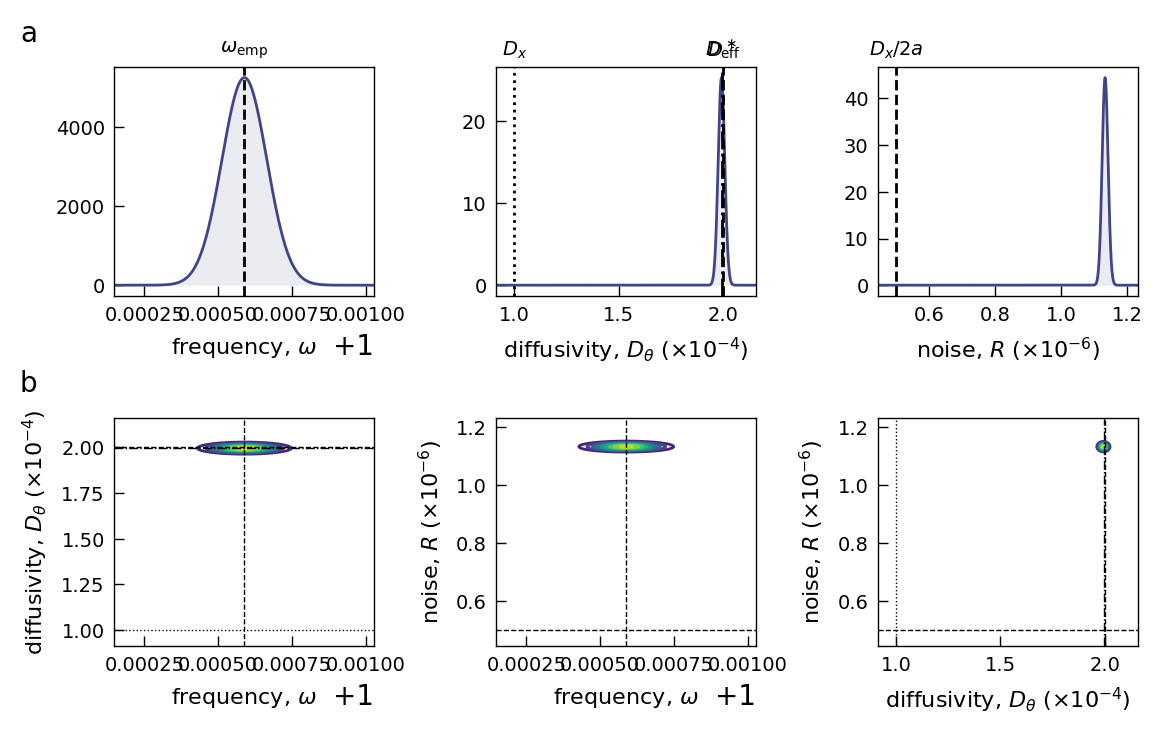

In [11]:
def stiff_case(cfg_c, path):
    """Simulate one no-noise window at the stiff-amplitude parameters of `cfg_c`, fit it, draw the posterior figure.

    Parameters
    ----------
    cfg_c : NoiseInjectionSweep.Config
        Oscillator (a, b, Dx), integrator step dt and sampling interval delta_t_inf of this case.
    path : Path
        PDF destination of the posterior figure.

    Returns
    -------
    fit, refs, rows
        As `infer`, the reference dict, and the rows from `summarize`. The omega reference is the realised
        mean frequency of the window.
    """
    a_c, b_c, Dx_c, dt_c = cfg_c.a, cfg_c.b, cfg_c.Dx, cfg_c.delta_t_inf
    D_eff_c, tau_r_c = cfg_c.D_eff, cfg_c.tau_r
    print(f"a = b = {a_c:g}, Dx = {Dx_c:.0e}, Delta t = {dt_c}:  Delta t / tau_r = {dt_c / tau_r_c:.0f}, "
          f"e^(-2a Dt) = {np.exp(-2 * a_c * dt_c):.1e}, D_eff = {D_eff_c:.1e}, sigma_rho^2 = {cfg_c.sigma_rho**2:.1e}")
    print(f"EKF term 2.4 x 2 D_eff Dt = {2.4 * 2 * D_eff_c * dt_c:.1e};  integrator dt = {cfg_c.dt:.0e} = tau_r/{tau_r_c / cfg_c.dt:.0f};  "
          f"Euler-Maruyama omega_sim - 1 = b dt/2a = {b_c * cfg_c.dt / (2 * a_c):.1e}")
    t0 = time.time()
    traj_c = NIS.simulate_ensemble(cfg_c, thin=True)
    print(f"integrated {cfg_c.N_steps:,} steps in {time.time() - t0:.0f} s")
    tk_c, yk_c, th_c, _ = NIS.make_window(traj_c, cfg_c, 0.0, N_INF, 0, noise_seed=0)
    del traj_c
    T_c = tk_c[-1] - tk_c[0]
    r_c = np.hypot(yk_c[:, 0], yk_c[:, 1])
    omega_emp = (th_c[-1] - th_c[0]) / T_c                   # realised mean frequency of the window [rad/time]
    print(f"N_INF = {N_INF}, T = {T_c:.0f} ({T_c / (2 * np.pi):.0f} cycles);  window check: Var(r - 1) = {np.var(r_c - 1):.2e} "
          f"vs Dx/2a = {Dx_c / (2 * a_c):.2e};  realised omega - 1 = {omega_emp - 1:+.2e}\n")

    fit_c = infer(tk_c, yk_c, cfg_c)
    refs_c = {'omega': [(omega_emp, '--', r'$\omega_{\rm emp}$', 'omega_emp')],
              'D': [(D_eff_c, '--', r'$D_{\rm eff}$', 'D_eff'), (Dx_c, ':', r'$D_x$', 'D_x'),
                    ref_Dstar(0.0, dt_c, a_c, b_c, Dx_c)],
              'R': [(Dx_c / (2 * a_c), '--', r'$D_x/2a$', 'Dx/2a')]}
    rows_c = summarize(fit_c, refs_c)
    assert fit_c['converged']
    m_, lo_, hi_ = rows_c['D']
    print(f"\nD_eff inside the 95 % interval: {lo_ <= D_eff_c <= hi_}   "
          f"(D_hat/D_eff = {m_ / D_eff_c:.4f}, interval [{lo_ / D_eff_c:.4f}, {hi_ / D_eff_c:.4f}])")
    fig = plot_parameter_posteriors(fit_c, refs_c, path)
    plt.show()
    return fit_c, refs_c, rows_c


cfg2b = replace(NIS.Config(), a=100.0, b=100.0, Dx=1e-4, dt=1e-3, delta_t_inf=2.16, n_rep=1, N_INF_max=N_INF)
fit2b, refs2b, rows2b = stiff_case(cfg2b, PLOTS / 'SL_Parameters_Case2b_StiffAmplitude.pdf')
summary['2b: no noise, Dt = 2.16, a=b=100, Dx=1e-4'] = (rows2b, refs2b, cfg2b.delta_t_inf)


### Case 3b · No added noise, $\Delta t = 0.02$, stiff amplitude ($a = b = 5000$)

Same sampling and same $D_x = 10^{-3}$ as case 3. The amplitude relaxes in $\tau_r = 10^{-4}$, 200 times faster
than the sampling, instead of 25 times slower. The radial variance is $\sigma_\rho^2 = 10^{-7}$: the measurement
sits on the limit cycle to within $3\times10^{-4}$, $R$ is tiny and the filter trusts the measured angle almost
completely. $D$ is then the chord diffusivity at lag $\Delta t$, which is $D_{\rm eff}(1-\tau_r/\Delta t)$.


a = b = 5000, Dx = 1e-03, Delta t = 0.02:  Delta t / tau_r = 200, e^(-2a Dt) = 1.4e-87, D_eff = 2.0e-03, sigma_rho^2 = 1.0e-07
EKF term 2.4 x 2 D_eff Dt = 1.9e-04;  integrator dt = 2e-05 = tau_r/5;  Euler-Maruyama omega_sim - 1 = b dt/2a = 1.0e-05


integrated 32,000,000 steps in 272 s
N_INF = 32000, T = 640 (102 cycles);  window check: Var(r - 1) = 1.10e-07 vs Dx/2a = 1.00e-07;  realised omega - 1 = +2.28e-03



EM: 24 iterations, converged = True, 1 s; Laplace covariance 40 s; EM contraction rate rho = 0.5000
               MAP              95% interval   relative to reference
 omega  1.0023e+00 [ 9.9736e-01,  1.0072e+00]   = 1.000 x omega_emp   [rad/time]
     D  2.0111e-03 [ 1.9801e-03,  2.0426e-03]   = 1.006 x D_eff, 2.011 x D_x, 1.011 x D*   [rad^2/time]
     R  1.1510e-07 [ 1.1333e-07,  1.1690e-07]   = 1.151 x Dx/2a   [length^2]

D_eff inside the 95 % interval: True   (D_hat/D_eff = 1.0055, interval [0.9900, 1.0213])
normalization (should be ~1): omega 1.0000, D 1.0000, R 1.0000, omega-D 1.0000, omega-R 1.0000, D-R 1.0000


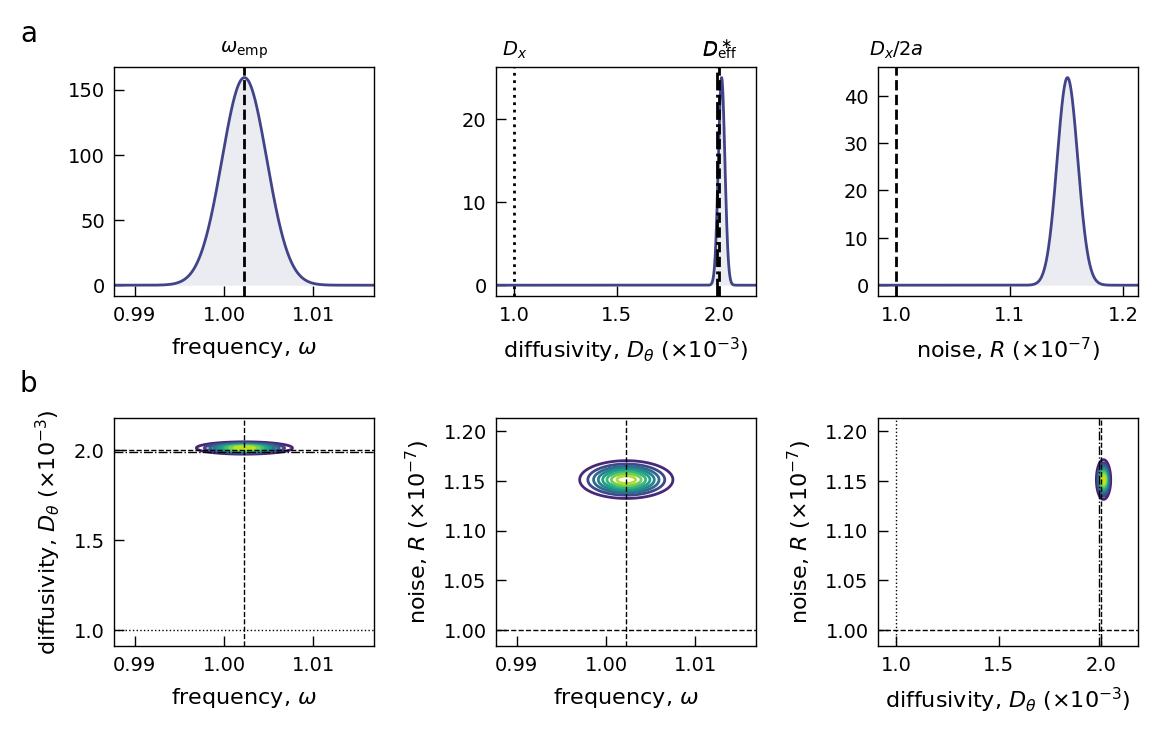

In [12]:
cfg3b = replace(NIS.Config(), a=5000.0, b=5000.0, dt=2e-5, delta_t_inf=0.02, n_rep=1, N_INF_max=N_INF)
fit3b, refs3b, rows3b = stiff_case(cfg3b, PLOTS / 'SL_Parameters_Case3b_StiffAmplitude.pdf')
summary['3b: no noise, Dt = 0.02, a=b=5000'] = (rows3b, refs3b, cfg3b.delta_t_inf)


### The limiting law, with all no-noise fits

$D^\ast/D_{\rm eff}$ against $\Delta t/\tau_r$ for the two samplings ($a$ varied with $b = a$), the law
$1 - \tau_r/\Delta t$, the Nyquist cap at $a = b = 1$, and the four no-noise fits with their 95 % intervals.


30 s


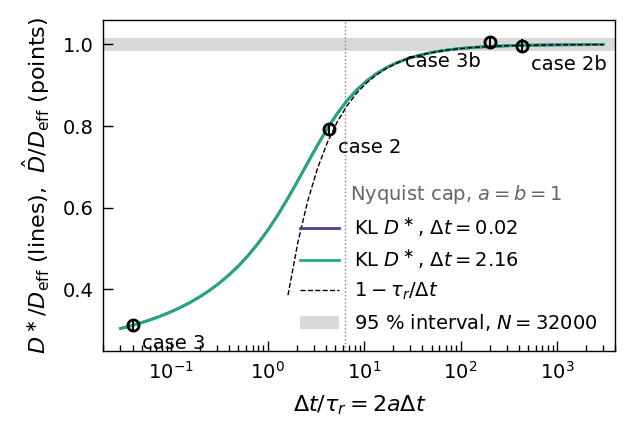

In [13]:
# the limiting law: D*/D_eff against Delta t / tau_r (no added noise), a varied with b = a, for both samplings
t0 = time.time()
x_grid = np.geomspace(0.03, 3000, 50)
fig, ax = fs.figax(6.5, 4.2)
for dt_c, col, lab in ((0.02, fs.C_DATA, r'$\Delta t = 0.02$'), (2.16, fs.C_MODEL, r'$\Delta t = 2.16$')):
    Dstar = np.array([kl_projection(0.0, dt_c, a=x / (2 * dt_c), b=x / (2 * dt_c), Dx=1e-3)['D'] / 2e-3 for x in x_grid])
    ax.semilogx(x_grid, Dstar, color=col, lw=1, label=rf'KL $D^\ast$, {lab}')
ax.semilogx(x_grid[x_grid > 1.5], 1 - 1 / x_grid[x_grid > 1.5], 'k', lw=0.5, ls='--', label=r'$1-\tau_r/\Delta t$')
ax.axhspan(1 - 0.0155, 1 + 0.0155, color='0.85', lw=0, label=r'95 % interval, $N = 32000$')
ax.axvline(2 * np.pi, color='0.5', lw=0.5, ls=':')
ax.text(2 * np.pi * 1.15, 0.62, r'Nyquist cap, $a = b = 1$', fontsize=fs.FS_TICK, color='0.4')
pts = [(fcfg.delta_t_inf / tau_r, summary['3: no noise, Dt = 0.02'][0]['D'], D_eff, '3'),
       (DT_2 / tau_r, summary[f'2: no noise, Dt = {DT_2}'][0]['D'], D_eff, '2'),
       (cfg2b.delta_t_inf / cfg2b.tau_r, rows2b['D'], cfg2b.D_eff, '2b'),
       (cfg3b.delta_t_inf / cfg3b.tau_r, rows3b['D'], cfg3b.D_eff, '3b')]
for x_c, (m, lo, hi), De, lab in pts:
    ax.errorbar([x_c], [m / De], [[(m - lo) / De], [(hi - m) / De]], fmt='o', ms=4, mfc='none', color='k', lw=0.7)
    left = lab == '3b'                                   # 3b and 2b sit close together: label one on each side
    ax.text(x_c * (0.8 if left else 1.25), m / De - 0.06, f'case {lab}', fontsize=fs.FS_TICK, ha='right' if left else 'left')
ax.set_xlim(0.02, 4000); ax.set_ylim(0.25, 1.06)
fs.style_axes(ax, xlabel=r'$\Delta t/\tau_r = 2a\Delta t$', ylabel=r'$D^\ast/D_{\rm eff}$ (lines),  $\hat D/D_{\rm eff}$ (points)')
fs.legend(ax, loc='lower right')
fs.save(fig, PLOTS / 'SL_LimitingRegime.pdf')
print(f"{time.time() - t0:.0f} s")
plt.show()


## Consistency with Example 1b (`../SyntheticPhaseNonlinearMeasurement`)

The estimator used here **is** the Example-1b estimator of `SyntheticPhaseNonlinearMeasurement.ipynb` and
`SPNM_Performance.ipynb`: `StuartLandauPhaseInference.py` is a copy of `SyntheticPhaseNonlinearMeasurement.py` that
differs only in docstrings (checked by the first cell below, which compares the two syntax trees), and `FastPhaseEM`
reproduces it to machine precision (`python FastPhaseEM.py`). The seven steps of the pipeline are the same; where a
setting differs, it is because SL data have no ground truth to seed from.

| step | Example 1b (`SPNM`) | this notebook (`infer`, = `NoiseInjectionSweep.fit_window`) |
|---|---|---|
| frequency seed | `estimate_frequency_fft` | same |
| initial phase | `estimate_initial_phase_regression`, window 6, crude $R$ = true $R$ | same function and window, crude $R = R_{\rm init} = \tfrac12\langle(\lvert y\rvert-1)^2\rangle$ |
| initial-state prior | $\mu_\theta = \varphi + \omega_{\rm FFT}t_1$, $\sigma_\theta = 2\,\sigma_\varphi$ | same, with a floor $\sigma_\theta \ge 0.01$ rad (active only when $R \lesssim 10^{-4}$, i.e. cases 2b, 3b) |
| parameter priors | $\omega \sim \mathcal N(\omega, \omega^2)$; $D, R \sim$ Inv-Gamma$(\alpha = 2, \beta = 2\times\text{true value})$ | $\omega \sim \mathcal N(\omega_{\rm FFT}, \omega_{\rm FFT}^2)$; $\alpha = 2$, $\beta_R = 2R_{\rm init}$, $\beta_D = 2D_{\rm init}$ with $D_{\rm init} = R_{\rm init}/20$ (prior mode at the data-driven seed instead of at the truth) |
| point estimate | Powell on the EKF posterior, or generalized EM (`em_map_parameters`, tol $10^{-5}$–$10^{-6}$, $\le 2000$ iterations), started from a draw of the prior | generalized EM only (`FastPhaseEM`, tol $10^{-5}$, cap 40 000), started from the prior mode |
| Laplace covariance | freeze $\mathbf H_k, \mathbf c_k$ at the nonlinear MAP, re-optimise the frozen posterior (L-BFGS-B), evaluate `posterior_information_frozen` there | freeze at the EM fixed point and evaluate there; the EM fixed point is a stationary point of the frozen posterior, so the two coincide (`SPNM` cell 52: $5\times10^{-5}$; checked below on case 3) |
| reported | MAP $\pm$ Laplace sd of $(\omega, \ln D, \ln R)$; $\omega$ band $\sqrt{2D/(N-1)\Delta t}$ | same; the $\omega$ band is the $\sqrt{2D/T}$ of `InferenceExplainer` §3 |

**Parameter conditions.** `SPNM_Performance` (cell 2) states three conditions, with the threshold $\varepsilon = 0.2$
drawn as the cross-over in its sweeps, plus the line $R = D\Delta t$ ($\kappa = 1$):

$$
\text{C1: } \sqrt{2D\Delta t} \ll 1,\qquad
\text{C2: } (2D\Delta t\,R)^{1/4} \ll 1,\qquad
\text{C3: } \frac{(\omega\Delta t)^2}{\sqrt R} \ll 1 .
$$

Their meaning in the language of `InferenceExplainer` §3d: **C1** is the phase step per sample, whose violation costs
$\ln\hat D \approx -2.4\times2D\Delta t$ (measured there on model data). **C2** is the prediction error of the EKF:
at the steady state with $Q = 2D\Delta t \ll R$, $P_{k|k-1} \approx \sqrt{QR}$, so $(2D\Delta t\,R)^{1/4} = \sqrt{P_{k|k-1}}$,
the quantity that must stay well below 1 rad for the linearisation of $\sin$ and $\cos$ (its violation inflates $R$
by $\tfrac38P^2$). **C3** is the supplement's "avoiding bias" condition. It is superseded: the drift $\omega\Delta t$ is
part of the prediction $\hat\theta_{k|k-1}$ and never enters the linearisation error, so no bias is attached to it.
The cases below violate C3 by up to four orders of magnitude without harm (cases 2b and 3b put $D_{\rm eff}$ inside
the 95 % interval). In `SPNM_Performance`'s own $\Delta t$ sweep $D$ is fixed, so C1 and C3 both grow with $\Delta t$
and cannot be told apart there; the degradation it shows is quantitatively the C1 bias ($-24\,\%$ at its
$\Delta t = 0.5$, where $2D\Delta t = 0.1$). The second cell below evaluates all three conditions, $\kappa$ and the two
`InferenceExplainer` quantities for every case; the third reproduces the Example-1b Laplace route on case 3.


In [14]:
# 1) the inference module is the Example-1b module: compare the two syntax trees with docstrings removed
import ast

sibling = Path('..') / 'SyntheticPhaseNonlinearMeasurement' / 'SyntheticPhaseNonlinearMeasurement.py'


def _code_tree(path):
    """AST dump of a module with every docstring removed (comments never enter the AST)."""
    tree = ast.parse(Path(path).read_text())
    for node in ast.walk(tree):
        body = getattr(node, 'body', None)
        if (isinstance(body, list) and body and isinstance(body[0], ast.Expr)
                and isinstance(getattr(body[0], 'value', None), ast.Constant) and isinstance(body[0].value.value, str)):
            node.body = body[1:] or [ast.Pass()]
    return ast.dump(tree)


if sibling.exists():
    identical = _code_tree(sibling) == _code_tree('StuartLandauPhaseInference.py')
    funcs = [n.name for n in ast.parse(sibling.read_text()).body if isinstance(n, ast.FunctionDef)]
    print(f"{sibling.name} vs StuartLandauPhaseInference.py: code identical ignoring docstrings and comments = {identical}")
    print(f"{len(funcs)} shared functions: " + ', '.join(funcs))
    assert identical
else:
    print(f"{sibling} not found: module-identity check skipped")


SyntheticPhaseNonlinearMeasurement.py vs StuartLandauPhaseInference.py: code identical ignoring docstrings and comments = True
23 shared functions: simulate_data, estimate_frequency_fft, estimate_initial_phase_regression, kalman_filter, neg_log_marginal_likelihood, neg_log_prior, neg_log_posterior, rts_smoother, theta_covariance, neg_log_marginal_likelihood_frozen, neg_log_posterior_frozen, freeze_linearization, grad_neg_log_posterior_frozen, em_update, em_map_parameters, prior_information, smoothing_statistics_frozen, complete_data_information_frozen, missing_information_frozen, posterior_information_frozen, _to_log_params, _to_natural_params, simulate_and_infer


In [15]:
# 2) the three SPNM_Performance conditions (threshold epsilon = 0.2), kappa, and the InferenceExplainer quantities, per case
EPS = 0.2
cond = []
for name, (rows, refs, dt_c) in summary.items():
    om, D, R = rows['omega'][0], rows['D'][0], rows['R'][0]
    D_eff_c = {nm: v for v, _, _, nm in refs['D']}['D_eff']
    Q = 2 * D * dt_c                                        # phase variance per sample [rad^2]
    P = Q / 2 + np.sqrt(Q**2 / 4 + Q * R)                   # steady-state predicted variance [rad^2]
    cond.append({'case': name.split(':')[0], 'dt': dt_c, 'kappa = R/(D dt)': R / (D * dt_c),
                 'C1 sqrt(2D dt)': np.sqrt(Q), 'C2 (2D dt R)^1/4': (Q * R)**0.25, 'C3 (w dt)^2/sqrt(R)': (om * dt_c)**2 / np.sqrt(R),
                 'sqrt(P_k|k-1)': np.sqrt(P), 'EKF bias 2.4 x 2D dt': 2.4 * Q,
                 'D_eff in 95%': bool(rows['D'][1] <= D_eff_c <= rows['D'][2])})
cond = pd.DataFrame(cond).set_index('case')
print(cond.to_string(float_format=lambda v: f'{v:.3g}'))
print(f"\nconditions met at epsilon = {EPS}:")
for key in ('C1 sqrt(2D dt)', 'C2 (2D dt R)^1/4', 'C3 (w dt)^2/sqrt(R)'):
    print(f"  {key:<22} " + ', '.join(f"{c}: {'ok' if v < EPS else 'VIOLATED x' + format(v / EPS, '.0f')}" for c, v in cond[key].items()))
assert (cond['C1 sqrt(2D dt)'] < EPS).all() and (cond['C2 (2D dt R)^1/4'] < EPS).all()
# C3 is superseded: at least one case violates it by far while D_eff sits inside its 95 % interval
assert ((cond['C3 (w dt)^2/sqrt(R)'] > 10 * EPS) & cond['D_eff in 95%']).any()


       dt  kappa = R/(D dt)  C1 sqrt(2D dt)  C2 (2D dt R)^1/4  C3 (w dt)^2/sqrt(R)  sqrt(P_k|k-1)  EKF bias 2.4 x 2D dt  D_eff in 95%
case                                                                                                                                 
1    0.02               502         0.00794            0.0316              0.00316         0.0321              0.000151         False
2    2.16             0.155          0.0828            0.0437                  203         0.0857                0.0164         False
3    0.02              22.9           0.005            0.0092               0.0235        0.00991              6.01e-05         False
2b   2.16           0.00263          0.0293           0.00559             4.39e+03         0.0294               0.00207          True
3b   0.02           0.00286         0.00897           0.00174                 1.18        0.00898              0.000193          True

conditions met at epsilon = 0.2:
  C1 sqrt(2D dt)         1: 

In [16]:
# 3) the Example-1b Laplace route on case 3: freeze at the EM fixed point, re-optimise the frozen posterior
#    (L-BFGS-B, as SPNM.simulate_and_infer does), and compare the frozen MAP and its covariance with `infer`'s
t0 = time.time()
lam_em = np.asarray(fit3['lambda_map'], float)
data3 = (tk3, yk3)
Hk3, ck3, _ = SLPI.freeze_linearization(lam_em, data3, fit3['state_priors'])
f_frozen = lambda x: SLPI.neg_log_posterior_frozen(x, data3, fit3['priors'], Hk3, ck3, param_mode='log')
nlp_em = f_frozen(lam_em)
# the analytic gradient of the reference module builds a dense N x N covariance (8 GB at N = 32000); use finite differences
res_fr = minimize(f_frozen, x0=lam_em, method='L-BFGS-B', options={'maxiter': 100, 'ftol': 1e-12, 'eps': 1e-6})
cov_fr = FastPhaseEM.posterior_information_fast(res_fr.x, data3, fit3['priors'], Hk3, ck3, param_type='log')['cov']
move = res_fr.x - lam_em
rel_cov = np.max(np.abs(cov_fr - fit3['cov'])) / np.abs(fit3['cov']).max()
print(f"frozen posterior re-optimised from the EM fixed point ({res_fr.nfev} evaluations, {time.time() - t0:.0f} s): {res_fr.message}")
print(f"shift of (omega, ln D, ln R): {move[0]:+.2e}, {move[1]:+.2e}, {move[2]:+.2e}   "
      f"(EM stopping tolerance 1e-5 relative, contraction rate rho = {fit3['rho']:.3f});  objective change {nlp_em - res_fr.fun:+.2e}")
print(f"max difference of the Laplace covariance, relative to its largest entry: {rel_cov:.1e}")
assert np.all(np.abs(move) < 2e-3) and rel_cov < 1e-2


frozen posterior re-optimised from the EM fixed point (32 evaluations, 167 s): CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
shift of (omega, ln D, ln R): -4.77e-07, +3.43e-04, +2.31e-06   (EM stopping tolerance 1e-5 relative, contraction rate rho = 0.845);  objective change +1.47e-04
max difference of the Laplace covariance, relative to its largest entry: 4.3e-05


## Summary

All values are MAPs with 95 % Laplace intervals, from the Example-1b estimator (consistency checked in the section above).

These posteriors come from the frozen linear-Gaussian surrogate, and that surrogate is misspecified for SL
data in every case. Their width is therefore within-model precision at $N_{\rm INF}=32000$. It says
nothing about the distance to $D_{\rm eff}$, which is a model-error bias, not sampling noise.

**Diffusivity.** Cases 1 and 2 land at the pseudo-true $D^\ast \approx 0.80\,D_{\rm eff}$ of `InferenceExplainer` §5:
case 2 within its 1 % realisation scatter, case 1 within the $\approx7\,\%$ single-realisation scatter at
$N_{\rm INF}=32000$. Case 3 lands at $D^\ast = 0.31\,D_{\rm eff}$. The remaining 20 % deficit in cases 1 and 2 is the
model error of the random-walk + white-noise description itself, not a lack of data: more samples narrow the
intervals around $D^\ast$, not around $D_{\rm eff}$.

**Limiting regime.** Cases 2b and 3b realise $\Delta t/\tau_r = 432$ and $200$ without added noise. There
$D^\ast = D_{\rm eff}(1-\tau_r/\Delta t)$ is within 0.5 % of $D_{\rm eff}$, and the fits put $D_{\rm eff}$ inside their
95 % intervals (last column of the table; from the realisation scatter alone a miss is expected about one time
in ten). At $a = b = 1$ this regime is unreachable without noise, because Nyquist caps $\Delta t/\tau_r$ at $2\pi$.

**Frequency.** In cases 1 and 3 the 95 % interval for $\omega$ misses $\omega_{\rm sim}$, but the
estimator is behaving correctly.
- The MAP follows this record's realised mean drift to $2\times10^{-5}$. For replicate 0 over $T=640$
  that drift is $0.99725$.
- Between realisations the realised drift scatters around $\omega_{\rm sim}$ by
  $\sqrt{2D_{\rm eff}/T}\approx 0.0025$.
- The Laplace interval scales as $\sqrt{D/T}$ with the underestimated $D$, so it is narrower than that
  scatter.

Case 2 confirms this. Its window is $T \approx 69\,000$, about 108 times longer, and its $\omega$ interval contains
$\omega_{\rm sim}$.

In [17]:
fmt = lambda m, lo, hi, ref: f"{m / ref:6.3f} [{lo / ref:6.3f}, {hi / ref:6.3f}]"
print(f"{'case':<40} {'omega / omega_ref':>24} {'D / D_eff':>24} {'D* / D_eff':>10} {'D / D*':>7} {'D_eff in 95%':>12} {'R / R_ref':>24}")
for name, (rows, refs, _) in summary.items():
    om, D, R = rows['omega'], rows['D'], rows['R']
    refD = {nm: v for v, _, _, nm in refs['D']}
    D_eff_c, Dstar, om_ref = refD['D_eff'], refD['D*'], refs['omega'][0][0]
    inside = D[1] <= D_eff_c <= D[2]
    print(f"{name:<40} {fmt(*om, om_ref):>24} {fmt(*D, D_eff_c):>24} {Dstar / D_eff_c:10.3f} {D[0] / Dstar:7.3f} "
          f"{str(inside):>12} {fmt(*R, refs['R'][0][0]):>24}")
print("\nomega_ref: omega_sim (section 0) for cases 1-3; the realised window frequency for cases 2b and 3b.")
print("R_ref:  " + ";  ".join(f"case {name.split(':')[0]}: {refs['R'][0][3]} = {refs['R'][0][0]:.4e}"
                              for name, (_, refs, _) in summary.items()))


case                                            omega / omega_ref                D / D_eff D* / D_eff  D / D* D_eff in 95%                R / R_ref
1: sigma_add = 0.125, Dt = 0.02            0.996 [ 0.992,  1.000]   0.788 [ 0.701,  0.885]      0.800   0.984        False   0.996 [ 0.985,  1.007]
2: no noise, Dt = 2.16                     1.000 [ 1.000,  1.000]   0.793 [ 0.780,  0.807]      0.800   0.991        False   1.061 [ 1.046,  1.078]
3: no noise, Dt = 0.02                     0.996 [ 0.993,  0.999]   0.313 [ 0.301,  0.326]      0.312   1.003        False   1.146 [ 1.133,  1.159]
2b: no noise, Dt = 2.16, a=b=100, Dx=1e-4   1.000 [ 1.000,  1.000]   0.997 [ 0.981,  1.012]      0.998   0.999         True   2.268 [ 2.233,  2.303]
3b: no noise, Dt = 0.02, a=b=5000          1.000 [ 0.995,  1.005]   1.006 [ 0.990,  1.021]      0.995   1.011         True   1.151 [ 1.133,  1.169]

omega_ref: omega_sim (section 0) for cases 1-3; the realised window frequency for cases 2b and 3b.
R_ref:  cas